In [1]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_core.messages import HumanMessage,BaseMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import MemorySaver

In [2]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
  messages : Annotated[list[BaseMessage],add_messages]
  


In [3]:
llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

def chat_node(state: ChatState):
  messages= state['messages']

  response = llm.invoke(messages)

  return{'messages': [response]}

In [4]:
memory = MemorySaver()

graph = StateGraph(ChatState)

graph.add_node('chat_node',chat_node)


graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot = graph.compile(checkpointer=memory)



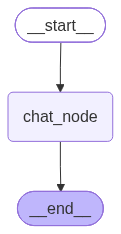

In [5]:
chatbot

In [6]:
initial_state  = {
  'messages':[HumanMessage(content='give me the distance from katraj to kalyani nagar hermes heritage phase 1')]
}
chatbot.invoke(initial_state)['messages'][-1].content

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [7]:
while True:
    user_message = input("You: ")
    print(f"You: {user_message}")

    if user_message.lower() == "exit":
        break

    response = chatbot.invoke(
        {
            "messages": [
                ("user", user_message)
            ]
        },
        config={
            "configurable": {
                "thread_id": "user_1"
            }
        }
    )

    print("Bot:", response["messages"][-1].content)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


You: hii
Bot: Hi there! How can I help you today?
You: 


d:\Langgaph\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3647: UserWarning: HumanMessage with empty content was removed to prevent API error
  warnings.warn(


Bot: 
You: Escape


d:\Langgaph\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3647: UserWarning: HumanMessage with empty content was removed to prevent API error
  warnings.warn(


Bot: That's a powerful word.

Are you:

*   Feeling like you need a break or a change of pace?
*   Looking for ways to relax or destress?
*   Thinking about an "escape room" challenge?
*   Referring to the "Escape" key on a keyboard?
*   Looking for something else entirely?

Tell me a bit more about what's on your mind!
You: exit
